<a href="https://colab.research.google.com/github/josecano8910/vocal-acoustic-feature-sandbox/blob/main/acoustic_sandbox.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vocal Acoustic Feature & Jitter Sandbox
Synthetic vocalization synthesis and frame-by-frame acoustic feature

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft

fs = 16000  # 16 kHz sample rate
duration = 2.0
t = np.linspace(0, duration, int(fs * duration), endpoint=False)

def generate_vocalization(t, base_f0=180.0, pitch_sweep=0.0, jitter_amount=0.0, brightness=1.0):
    rng = np.random.default_rng(42)
    inst_f0 = base_f0 + (pitch_sweep * t) + rng.normal(0, jitter_amount, size=len(t))
    phase = 2 * np.pi * np.cumsum(inst_f0) / fs

    signal = np.zeros_like(t)
    for h in range(1, 6):
        amplitude = (1.0 / (h ** (1.5 / brightness)))
        signal += amplitude * np.sin(h * phase)

    envelope = np.sin(np.pi * t / duration) ** 0.5
    return signal * envelope

calm_call = generate_vocalization(t, base_f0=170.0, pitch_sweep=5.0, jitter_amount=0.5, brightness=0.8)
aroused_call = generate_vocalization(t, base_f0=230.0, pitch_sweep=45.0, jitter_amount=8.0, brightness=1.8)
print("Synthesized arrays:", calm_call.shape, aroused_call.shape)


Synthesized arrays: (32000,) (32000,)


In [5]:
def extract_acoustic_features(signal, fs, frame_ms=40, hop_ms=10):
    frame_len = int(fs * frame_ms / 1000)  # 40ms = 640 samples
    hop_len = int(fs * hop_ms / 1000)      # 10ms = 160 samples

    times, rms_vals, f0_vals, centroids = [], [], [], []
    freqs = np.fft.rfftfreq(frame_len, d=1/fs)

    for start in range(0, len(signal) - frame_len, hop_len):
        frame = signal[start:start + frame_len]
        windowed = frame * np.hanning(frame_len)

        # 1. RMS Energy (Loudness)
        rms = np.sqrt(np.mean(frame ** 2))

        # 2. Spectral Centroid (Brightness)
        mag = np.abs(np.fft.rfft(windowed))
        centroid = np.sum(freqs * mag) / (np.sum(mag) + 1e-12)

        # 3. Fundamental Frequency f0 (Pitch via Autocorrelation)
        corr = np.correlate(windowed, windowed, mode='full')[frame_len - 1:]
        min_lag = int(fs / 400)  # 40 samples -> 400 Hz ceiling
        max_lag = int(fs / 80)   # 200 samples -> 80 Hz floor
        peak_lag = np.argmax(corr[min_lag:max_lag]) + min_lag
        f0 = fs / peak_lag

        times.append((start + frame_len / 2) / fs)
        rms_vals.append(rms)
        f0_vals.append(f0)
        centroids.append(centroid)

    return np.array(times), np.array(rms_vals), np.array(f0_vals), np.array(centroids)

t_c, rms_c, f0_c, cent_c = extract_acoustic_features(calm_call, fs)
t_a, rms_a, f0_a, cent_a = extract_acoustic_features(aroused_call, fs)
print(f"Extracted {len(t_c)} overlapping frames per signal.")


Extracted 196 overlapping frames per signal.


In [6]:
def compute_local_jitter(f0_series):
    # Convert frequency (Hz) to cycle duration / period T (seconds)
    periods = 1.0 / f0_series
    diffs = np.abs(np.diff(periods))
    return (np.mean(diffs) / np.mean(periods)) * 100  # Percentage

print(f"Calm Call    -> Mean f0: {np.mean(f0_c):.1f} Hz | Local Jitter: {compute_local_jitter(f0_c):.2f}%")
print(f"Aroused Call -> Mean f0: {np.mean(f0_a):.1f} Hz | Local Jitter: {compute_local_jitter(f0_a):.2f}%")


Calm Call    -> Mean f0: 175.8 Hz | Local Jitter: 0.03%
Aroused Call -> Mean f0: 275.1 Hz | Local Jitter: 0.18%


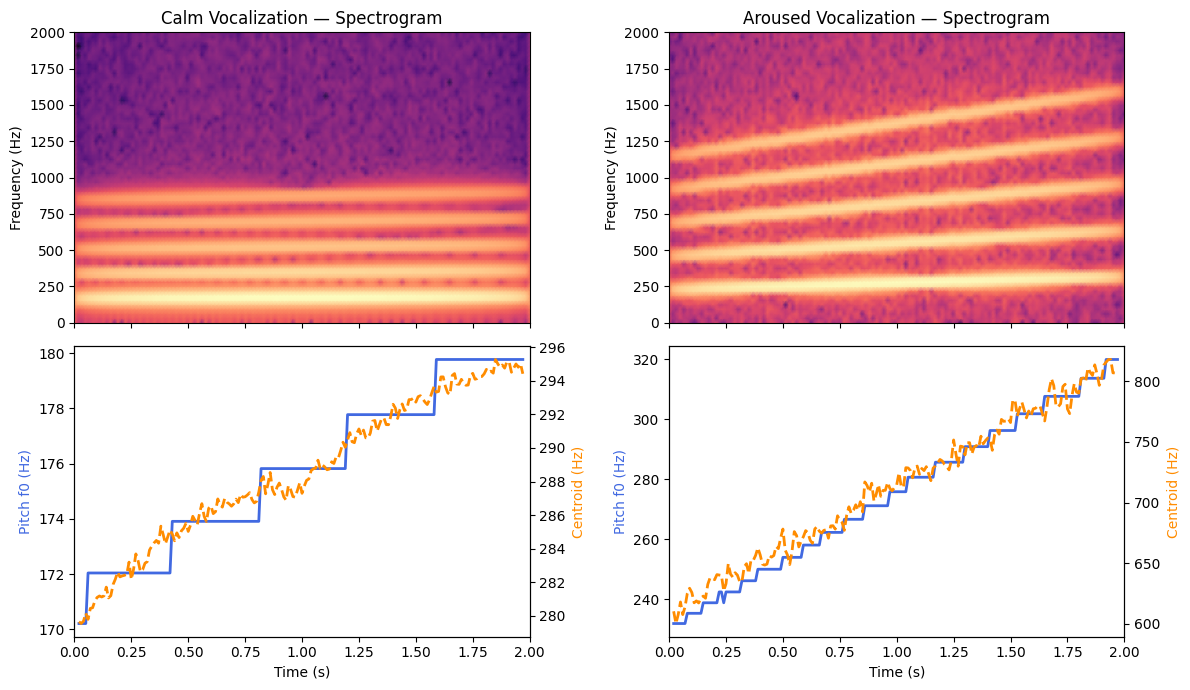

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

for idx, (sig, t_f, f0, cent, label) in enumerate([
    (calm_call, t_c, f0_c, cent_c, "Calm Vocalization"),
    (aroused_call, t_a, f0_a, cent_a, "Aroused Vocalization")
]):
    f_stft, t_stft, Zxx = stft(sig, fs=fs, nperseg=512)
    axes[0, idx].pcolormesh(t_stft, f_stft, 20 * np.log10(np.abs(Zxx) + 1e-8), shading='gouraud', cmap='magma')
    axes[0, idx].set_ylim(0, 2000)
    axes[0, idx].set_title(f"{label} — Spectrogram")
    axes[0, idx].set_ylabel("Frequency (Hz)")

    axes[1, idx].plot(t_f, f0, color='royalblue', lw=2)
    axes[1, idx].set_ylabel("Pitch f0 (Hz)", color='royalblue')
    axes[1, idx].set_xlabel("Time (s)")

    ax_twin = axes[1, idx].twinx()
    ax_twin.plot(t_f, cent, color='darkorange', lw=2, linestyle='--')
    ax_twin.set_ylabel("Centroid (Hz)", color='darkorange')

plt.tight_layout()
plt.savefig("acoustic_comparison.png", dpi=150)
plt.show()


In [8]:
# Boundary test: shrinking analysis frame from 40ms to 10ms
_, _, f0_short_window, _ = extract_acoustic_features(calm_call, fs, frame_ms=10, hop_ms=5)
print(f"40ms window mean f0: {np.mean(f0_c):.1f} Hz | 10ms window mean f0: {np.mean(f0_short_window):.1f} Hz")


40ms window mean f0: 175.8 Hz | 10ms window mean f0: 193.6 Hz


### Window-Length Boundary Check
When `frame_ms` is reduced from **40 ms** (640 samples) to **10 ms** (160 samples), the autocorrelation tracker fails to resolve the true ~175 Hz fundamental pitch because a single 175 Hz wave cycle lasts ~5.7 ms—leaving less than two full cycles inside a 10 ms frame (and fewer than one full cycle at the 80 Hz lower bound). Reliable time-domain pitch tracking requires an analysis window spanning at least 2–3 fundamental periods (30–40 ms).
